In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

## Post-Cleaning EDA
__Types of analysis visualizations__
- Univariate analysis: Single variables/column analysis.
- Bivariate analysis: Two variables
- Multivariate analysis: Analysis for more than two variables/columns.( 3 or more)

### Univariate Analysis



/tmp/ipykernel_100126/4088026907.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='status_group', data=filtered_data_df,palette='colorblind')


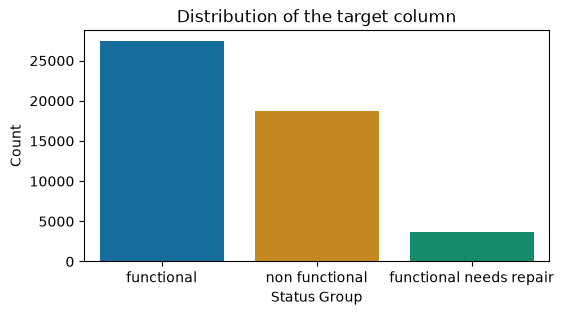

In [113]:
# Distribution of the target variable

filtered_data_df = pd.read_csv('../data/cleaned_water_pump_data.csv')
plt.figure(figsize=(6,3))
sns.countplot(x='status_group', data=filtered_data_df,palette='colorblind')
plt.title('Distribution of the target column')
plt.xlabel('Status Group')
plt.ylabel('Count')
plt.show()

/tmp/ipykernel_100126/931472400.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='waterpoint_type_group', data=filtered_data_df, palette='colorblind')


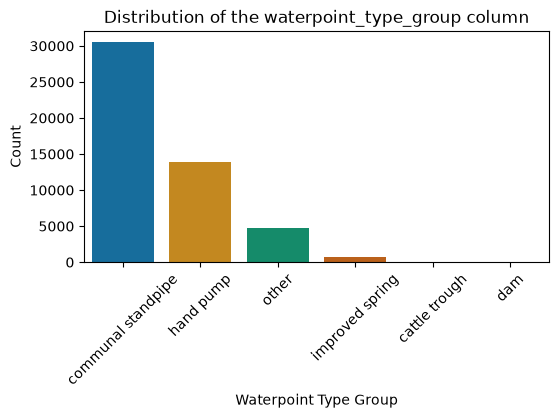

In [114]:
# Distribution of the water_type_group variable

filtered_data_df = pd.read_csv('../data/cleaned_water_pump_data.csv')
plt.figure(figsize=(6,3))
sns.countplot(x='waterpoint_type_group', data=filtered_data_df, palette='colorblind')
plt.title('Distribution of the waterpoint_type_group column')
plt.xlabel('Waterpoint Type Group')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

#### Numerical column
- Distribution reveals how data points span across a specific range
__Normal Distribution__
![Normal Distribution](https://media.geeksforgeeks.org/wp-content/uploads/20260707120709586913/a_normal_distribution1.webp)

__Other types of distribution



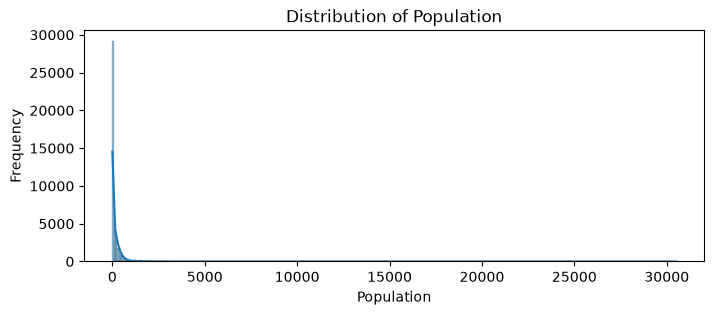

In [115]:
# PLot the distribution of population variable

plt.figure(figsize=(8, 3))
sns.histplot(filtered_data_df,x='population', kde=True)
plt.title('Distribution of Population')
plt.xlabel('Population')
plt.ylabel('Frequency')
plt.show()

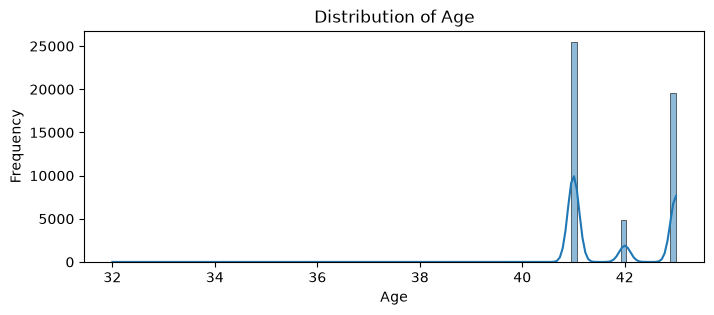

In [116]:
# PLot the distribution of population variable

plt.figure(figsize=(8, 3))
sns.histplot(filtered_data_df, x='age', kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

##multi modal distribution of the age variable, with peaks around 0, 10, and 20 years. This suggests that there are distinct age groups within the dataset, which could be related to the functionality of water pumps. Further analysis may be needed to understand the factors contributing to these age groups and their impact on water pump functionality.

### Bivariate Analysis

Categorical vs Categorical

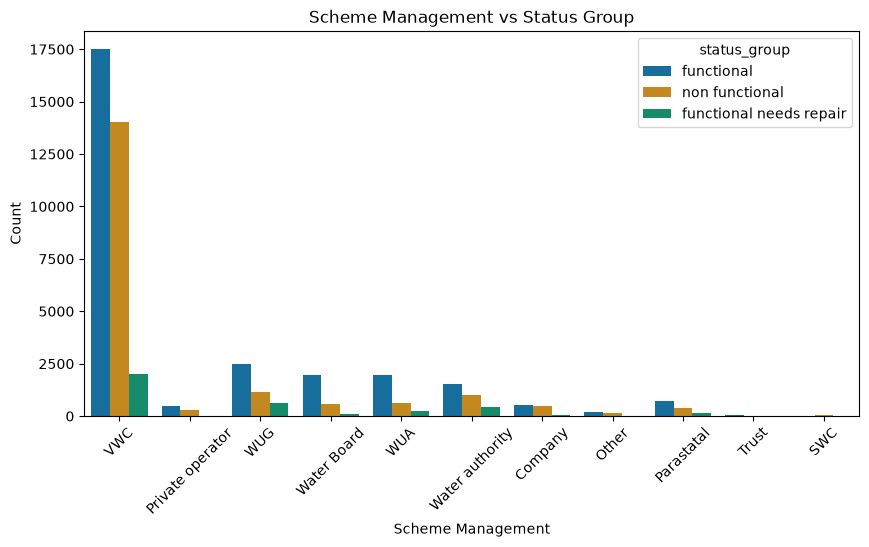

In [117]:
filtered_data_df.columns

# Scheme management vs status group

# hue is used to separate the bars by the status_group variable, allowing us to see how the distribution of scheme_management varies across different status groups. like keys


# Scheme management vs status group
plt.figure(figsize=(10, 5))
sns.countplot(x='scheme_management', hue='status_group',
              data=filtered_data_df, palette='colorblind')
plt.title('Scheme Management vs Status Group')
plt.xlabel('Scheme Management')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show() 



### Numerical vs Categorical

/tmp/ipykernel_100126/1095746556.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='status_group', y='gps_height',


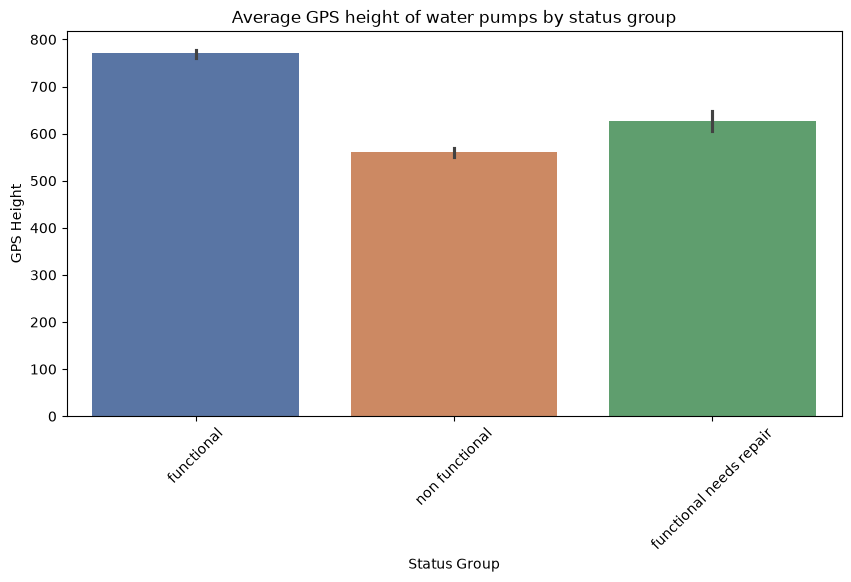

In [118]:

plt.figure(figsize=(10, 5))
sns.barplot(x='status_group', y='gps_height',
            data=filtered_data_df, palette='deep')
plt.title('Average GPS height of water pumps by status group')
plt.xlabel('Status Group')
plt.ylabel('GPS Height')
plt.xticks(rotation=45)
plt.show()

### Numerical vs Numerical

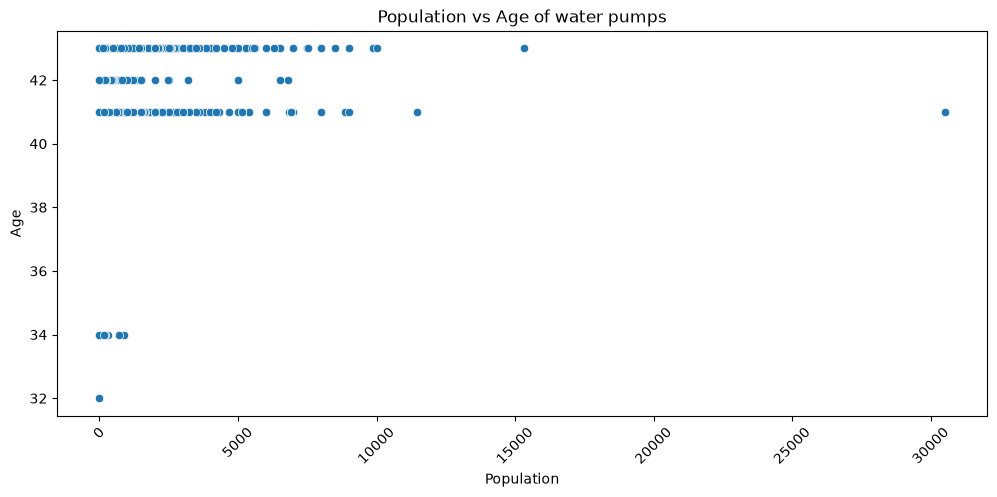

In [119]:

plt.figure(figsize=(12, 5))
sns.scatterplot(x='population', y='age',
            data=filtered_data_df)
plt.title('Population vs Age of water pumps')
plt.xlabel('Population')
plt.ylabel('Age')
plt.xticks(rotation=45)
plt.show()

### Multivariate analysis

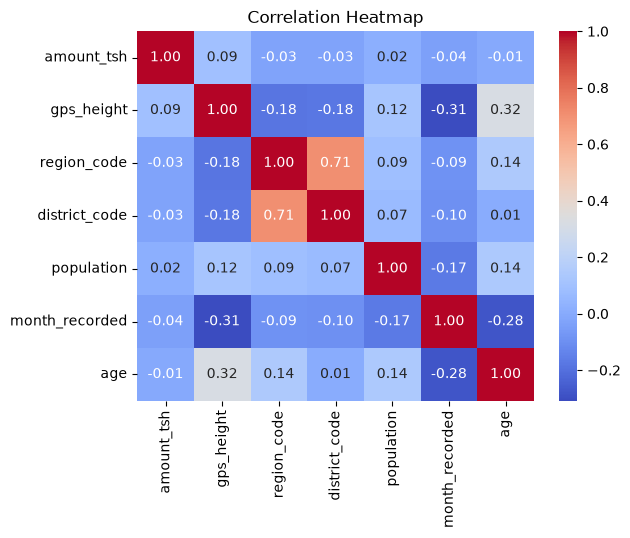

In [120]:
# Correlation heatmap

numerical_cols  =  filtered_data_df.select_dtypes(include=['int', 'float']).columns.tolist()
correlation = filtered_data_df[numerical_cols].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

__Correlation scale__
-1 ------------0--------------------1

-1 to -0.7 => Strong negative correlation
-0.6 to -0.1 => weak negative correlation
 0=> no correlation
 0.1 to 0.6 => weak positive correlation
 0.7 to 1 => strong positive correlation
 1=> Strong positive correlation

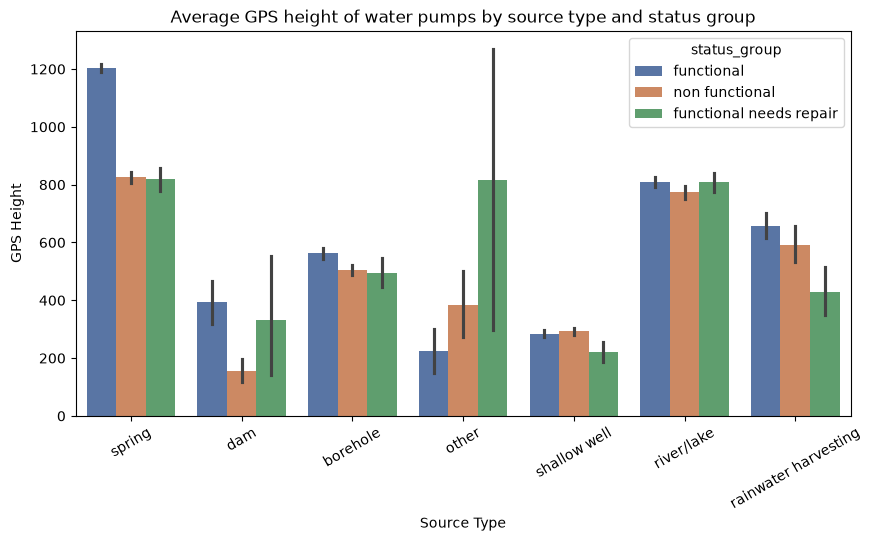

In [121]:

plt.figure(figsize=(10, 5))
sns.barplot(x='source_type', y='gps_height',
            data=filtered_data_df, hue='status_group', palette='deep', estimator='mean')
plt.title('Average GPS height of water pumps by source type and status group')
plt.xlabel('Source Type')
plt.ylabel('GPS Height')
plt.xticks(rotation=30)
plt.show()

In [122]:
filtered_data_df.columns

Index(['amount_tsh', 'gps_height', 'region', 'basin', 'region_code',
       'construction_year', 'date_recorded', 'district_code', 'population',
       'public_meeting', 'scheme_management', 'permit',
       'extraction_type_class', 'management_group', 'payment_type',
       'water_quality', 'quantity_group', 'source_type',
       'waterpoint_type_group', 'status_group', 'month_recorded', 'age'],
      dtype='str')

## Hypothesis Testing
__Hypothesis testing__ is a statistical methods used to determine whether there is enough evidence in data to support a claim about relationship between variables

Hypothesis testing helps us in:
- Feature selection
- EDA( to evaluate and see if the data makes statistical sense)
- Understanding variable relationship
- Reduction of irrelevant features

### Core Idea of hypothesis testing.
__Null Hypothesis(H<sub>0</sub>):__ This is the default assumption that there's no effect , no elationship,no diference between groups

_Examples_: Gender and loan approval are independent Meaning the feature gender dosn't aftect the target loan approval and the observed is by random chance.

__Alternative Hypothesis(H<sub>1</sub>):__ this is what we are trying to approve
_Examples_: Gender and loan approval are associated(Meaning that there's a predictive information from the gender feature).

__Definiton of terms__
- Alpha/Level of significanc($\alpha$): It is the 'cutoff' for statistical significance.Mostly used alphas is 0.05/5%,0.01/1%
- p-value: The probability of observing results atleast as extreme as the current data assuming the null hypothesis is true

_Evaluation or judgement_
|Condition|Decision         |
|---------|-----------      |
|p<= alpha|  Reject H0      |
|p>alpha  |Fail to reject H0|

- Type I Error(False Positive): When we reject the null pypothseis that is actually true
- Type II Error(False Negative): When we fail not to reject the null hypothesis

_How do you choose the best hypothesis_
